# 3

## (a)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=0)
p, sigma = 1000, 1.0
n_values = np.array([50, 100, 200, 400, 800, 1600])
trials = 100
results = []

for n in n_values:
    measurements = []
    for _ in range(trials):
        X = rng.normal(0, 1, size=(n, p))
        epsilon = rng.normal(0, sigma, size=n)
        measurements.append(np.max(np.abs(X.T @ epsilon / n)))
    measurements = np.array(measurements)
    lam0 = sigma * np.sqrt(2 * np.log(p) / n)
    results.append((n, measurements.mean(), measurements.std(ddof=1),
                    measurements.std(ddof=1) / np.sqrt(trials), lam0,
                    measurements.mean() / lam0))

results = np.array(results)
slope = np.polyfit(np.log(results[:, 0]), np.log(results[:, 1]), 1)[0]
results, slope

(array([[5.00000000e+01, 4.88022862e-01, 6.42583230e-02, 6.42583230e-03,
         5.25652177e-01, 9.28414042e-01],
        [1.00000000e+02, 3.43539483e-01, 3.68017559e-02, 3.68017559e-03,
         3.71692219e-01, 9.24257935e-01],
        [2.00000000e+02, 2.43493566e-01, 2.70290778e-02, 2.70290778e-03,
         2.62826088e-01, 9.26443671e-01],
        [4.00000000e+02, 1.73718932e-01, 1.70579842e-02, 1.70579842e-03,
         1.85846109e-01, 9.34746132e-01],
        [8.00000000e+02, 1.21766597e-01, 1.32863779e-02, 1.32863779e-03,
         1.31413044e-01, 9.26594443e-01],
        [1.60000000e+03, 8.64825114e-02, 8.51083136e-03, 8.51083136e-04,
         9.29230547e-02, 9.30689500e-01]]),
 np.float64(-0.4988155200940045))

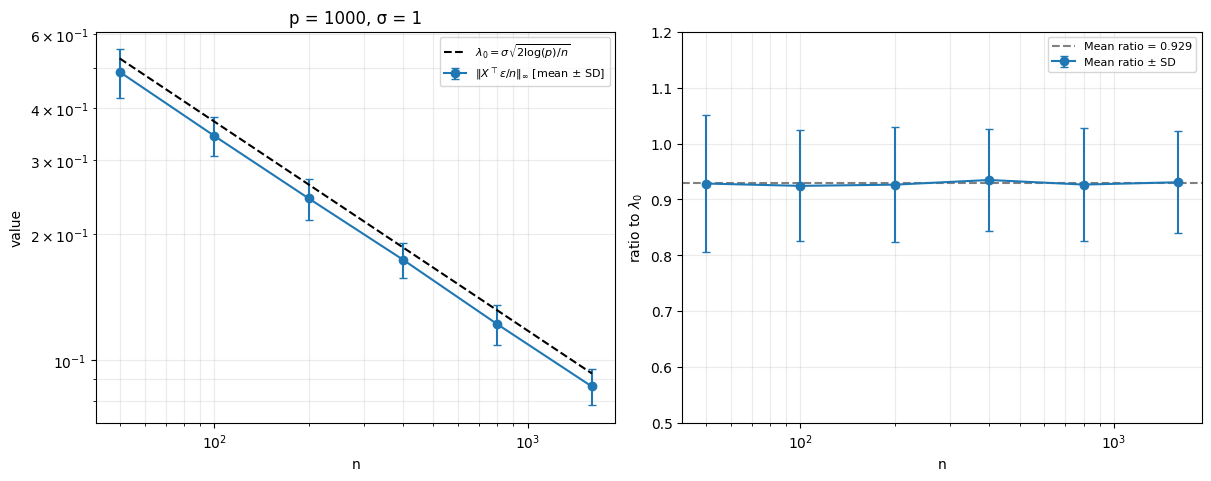

In [5]:
from matplotlib.ticker import ScalarFormatter

fig, axes = plt.subplots(1, 2, figsize=(12, 4.7), layout="constrained")
n, avg, sd, se, lam, ratio = results.T

axes[0].errorbar(n, avg, yerr=sd, fmt="o-", capsize=3, label=r"$\|X^\top\varepsilon/n\|_\infty$ [mean $\pm$ SD]")
axes[0].plot(n, lam, "k--", label=r"$\lambda_0=\sigma\sqrt{2\log(p)/n}$")
axes[0].set(xscale="log", yscale="log", xlabel="n",
            ylabel="value", title="p = 1000, σ = 1")
axes[0].grid(True, which="both", alpha=.25)
axes[0].legend(fontsize=8)

axes[1].errorbar(n, ratio, yerr=sd / lam, fmt="o-", capsize=3, label="Mean ratio ± SD")
axes[1].axhline(np.mean(ratio), linestyle="--", color="gray", label=f"Mean ratio = {np.mean(ratio):.3f}")
axes[1].set(xscale="log", xlabel="n", ylabel=r"ratio to $\lambda_0$")
axes[1].set_ylim(.5, 1.2)
axes[1].grid(True, which="both", alpha=.25)
axes[1].legend(fontsize=8)

plt.show()

The fitted slope of the log-log plot is roughly $-0.5$. The ratio hovers around 
a constant $0.92$. From lecture 7, the union bound over Gaussian tails shows that:
$$
    \left\|\frac{1}{n}\epsilon^\top X\right\|_\infty \leq C\sigma \sqrt{\frac{\log p}n}
$$
for some constant $C > 0$, and then chooses $\lambda = 2C\sigma\sqrt{\frac{\log p}{n}}$.
This shows that noise level scales as
$$
    \left\|\frac{1}{n}\epsilon^\top X\right\|_\infty = O_p\left(\sigma \sqrt{\frac{\log p}n}\right)
$$.
We have $\lambda_0 = \sigma \sqrt{\frac{2\log p}{n}}$. Both expressions have the
same dependence on $n$ and $p$. Since $p = 1000$, $\sigma = 1$ are fixed, both
scale to $n^{-1/2}$. This explains why the experimentally observed ratio remains
approximately constant at around $0.92$ while $n$ increases. The constant $\sqrt{2}$
in $\lambda_0$ is asymptotically sharp for the maximum of independent Gaussian
variables, but is slightly conservative for finite $p$. Our observed ratio indicates
that $\lambda_0$ slightly overestimates the expected noise level when $p = 1000$.

## (b)

In [2]:
from scipy.optimize import linprog
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

rng = np.random.default_rng(seed=0)
T = 20
p, sigma = 256, 0
n_values = np.arange(8, 257, 8)
k_values = np.arange(1, 64, 2)

In [ ]:
# default data generation 

success = np.zeros((len(n_values), len(k_values)), dtype=float)
for i, n in enumerate(n_values):
    for j, k in enumerate(k_values):
        for trial in range(T):
            X = rng.standard_normal((n, p))
            beta = np.zeros(p)
            support = rng.choice(p, size=k, replace=False)
            beta[support] = rng.choice([-1.0, 1.0], size=k)
            y = X @ beta
            # beta = beta_plus - beta_minus, beta_plus, beta_minus >= 0
            # Objective min 1^T beta_plus + 1^T beta_minus, subject to X beta = y
            fit = linprog(np.ones(2*p), A_eq=np.concatenate([X, -X], axis=1),
                          b_eq=y, bounds=(0, None), method='highs')
            if fit.success:
                beta_hat = fit.x[:p] - fit.x[p:]
                if np.linalg.norm(beta_hat-beta) <= 1e-4*np.linalg.norm(beta):
                    success[i,j] += 1

In [ ]:
# parallelized

# Run all T trials for one (n, k) configuration
def run_config(i, j, n, k, seed):
    rng = np.random.default_rng(seed)
    successes = 0

    with threadpool_limits(limits=1):
        for trial in range(T):
            X = rng.standard_normal((n, p))
            beta = np.zeros(p)
            support = rng.choice(p, size=k, replace=False)
            beta[support] = rng.choice([-1.0, 1.0], size=k)
            y = X @ beta

            # beta = beta_plus - beta_minus
            # Objective: min 1^T beta_plus + 1^T beta_minus
            # Subject to: X beta = y
            fit = linprog(
                np.ones(2 * p),
                A_eq=np.concatenate([X, -X], axis=1),
                b_eq=y,
                bounds=(0, None),
                method="highs",
            )

            if fit.success:
                beta_hat = fit.x[:p] - fit.x[p:]

                if np.linalg.norm(beta_hat - beta) <= 1e-4 * np.linalg.norm(beta):
                    successes += 1

    return i, j, successes / T

rng = np.random.SeedSequence(0)
seeds = rng.spawn(len(n_values) * len(k_values))

n_jobs = 8

# Parallelize across (n, k) configurations
results = Parallel(
    n_jobs=n_jobs,
    backend="loky",
    verbose=10
)(
    delayed(run_config)(i, j, n, k, seeds[i * len(k_values) + j])
    for i, n in enumerate(n_values)
    for j, k in enumerate(k_values)
)

# Reconstruct success probability matrix
success = np.zeros((len(n_values), len(k_values)))

for i, j, rate in results:
    success[i, j] = rate

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    1.2s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    1.3s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    1.3s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    1.5s
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    1.6s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:    1.8s
[Parallel(n_jobs=8)]: Done  56 tasks      | elapsed:    1.9s
[Parallel(n_jobs=8)]: Done  69 tasks      | elapsed:    2.2s
[Parallel(n_jobs=8)]: Done  82 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done  97 tasks      | elapsed:    3.0s
[Parallel(n_jobs=8)]: Done 112 tasks      | elapsed:    3.3s
[Parallel(n_jobs=8)]: Done 129 tasks      | elapsed:    3.8s
[Parallel(n_jobs=8)]: Done 146 tasks      | elapsed:    4.4s
[Parallel(n_jobs=8)]: Done 165 tasks      | elapsed:    5.1s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:    5.9s
[Parallel(

In [17]:
np.save("success.npy", success)

C: 1.010011803526003
n50: [(np.int64(1), np.int64(8)), (np.int64(3), np.int64(24)), (np.int64(5), np.int64(32)), (np.int64(7), np.int64(32)), (np.int64(9), np.int64(40)), (np.int64(11), np.int64(48)), (np.int64(13), np.int64(56)), (np.int64(15), np.int64(56)), (np.int64(17), np.int64(64)), (np.int64(19), np.int64(72)), (np.int64(21), np.int64(80)), (np.int64(23), np.int64(80)), (np.int64(25), np.int64(80)), (np.int64(27), np.int64(88)), (np.int64(29), np.int64(96)), (np.int64(31), np.int64(96)), (np.int64(33), np.int64(104)), (np.int64(35), np.int64(112)), (np.int64(37), np.int64(112)), (np.int64(39), np.int64(112)), (np.int64(41), np.int64(120)), (np.int64(43), np.int64(120)), (np.int64(45), np.int64(120)), (np.int64(47), np.int64(128)), (np.int64(49), np.int64(128)), (np.int64(51), np.int64(136)), (np.int64(53), np.int64(144)), (np.int64(55), np.int64(136)), (np.int64(57), np.int64(144)), (np.int64(59), np.int64(144)), (np.int64(61), np.int64(144)), (np.int64(63), np.int64(152))]


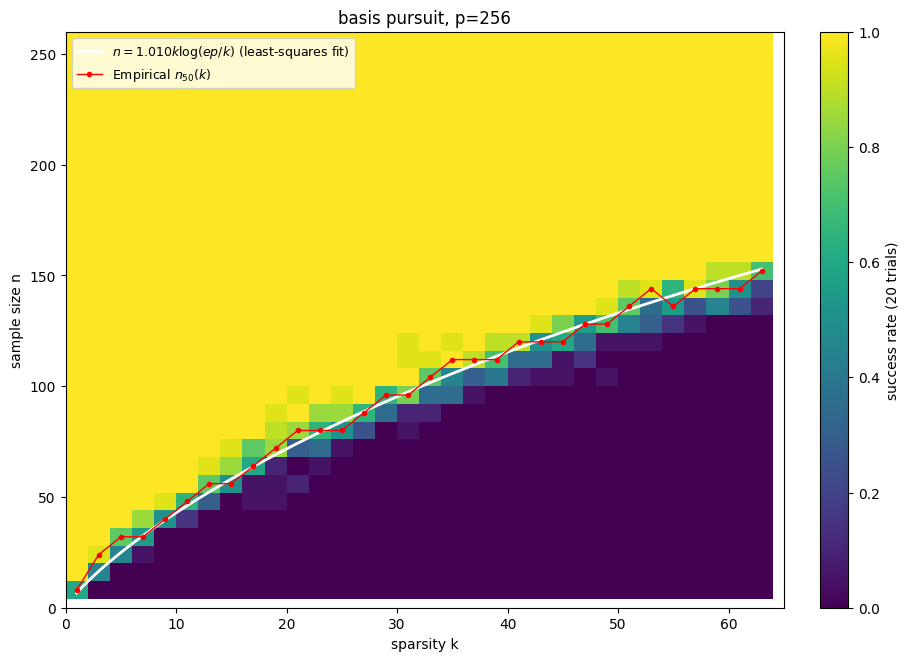

In [19]:
n50 = np.array([n_values[np.where(success[:,j] >= 0.5)[0][0]] if np.any(success[:,j]>=0.5)
                else np.nan for j in range(len(k_values))])
factor = k_values * np.log(np.e * p / k_values)
valid = np.isfinite(n50)
C = np.sum(factor[valid]*n50[valid]) / np.sum(factor[valid]**2)

fig, ax = plt.subplots(figsize=(9,6.5), layout='constrained')
k_edges = np.r_[k_values[0] - (k_values[1] - k_values[0]) / 2, (k_values[:-1] + k_values[1:]) / 2,
                k_values[-1] + (k_values[-1] - k_values[-2]) / 2]
n_edges = np.r_[n_values[0] - (n_values[1] - n_values[0]) / 2, (n_values[:-1] + n_values[1:]) / 2,
                n_values[-1] + (n_values[-1] - n_values[-2]) / 2]
heat = ax.pcolormesh(k_edges, n_edges, success, vmin=0, vmax=1, cmap='viridis', shading='flat')
k_dense = np.linspace(1, 63, 400)
ax.plot(k_dense, C * k_dense * np.log(np.e * p / k_dense), color='white', lw=2,
        label=rf'$n = {C:.3f} k\log(ep/k)$ (least-squares fit)')
ax.plot(k_values[valid], n50[valid], color='red', marker='o', lw=1, markersize=3,
        label=r'Empirical $n_{50}(k)$')
ax.set(xlabel='sparsity k', ylabel='sample size n', title='basis pursuit, p=256')
ax.set_xlim(0, 65)
ax.set_ylim(0, 260)
ax.legend(loc='upper left', fontsize=9)
cbar = fig.colorbar(heat, ax=ax)
cbar.set_label(f'success rate ({T} trials)')
print('C:',C)
print('n50:',list(zip(k_values,n50)))

i. The shape of the empirical boundary (red dotted lines) follows $k \log(ep/k)$, $C = 1.01$.  
ii. The result predicts the shape of the boundary because the required sample size
scales proportionally to $k \log(ep/k)$. However, the theorem doesn't specify the
exact constant $C'$, so it cannot determine the precise sample size at which
exact recovery becomes likely. Furthermore, the condition provides a sufficient
condition for exact recovery, not the threshold for 50% recovery as in i., thus 
the location is never precisely known. The transition is sharp because Gaussian
random matrices exhibit strong concentration properties. Below the critical sample
size, basis pursuit often can't uniquely recover the sparse signal, but once $n$ becomes
sufficiently large relative to $k \log(ep/k)$, the necessary conditions for exact
recovery take root. Consequently, the success probability is sharp.

## (c)

In [7]:
from sklearn.linear_model import Lasso

p = 512
sigma = 1
k = 10
n_values = np.array([200, 400, 800, 1600, 3200])
k_values = np.array([5, 10, 15, 20, 25, 30])
configs = [(int(n), 10) for n in n_values] + [(800, int(k)) for k in k_values if k != 10]

def run_config(n, k, seed):
    rng = np.random.default_rng(seed)
    values = []
    with threadpool_limits(limits=1):
        for _ in range(T):
            X = rng.standard_normal((n, p))
            beta = np.zeros(p)
            support = rng.choice(p, size=k, replace=False)
            beta[support] = rng.choice([-1.0, 1.0], size=k)
            eps = rng.normal(0, sigma, size=n)
            y = X @ beta + eps
            lam = 0.5 * sigma * np.sqrt(2 * np.log(p) / n)
            fit = Lasso(alpha=lam, fit_intercept=False, max_iter=20000, tol=1e-7)
            fit.fit(X, y)
            values.append(np.sum((fit.coef_ - beta) ** 2))
    values = np.asarray(values)
    return (n, k, float(values.mean()), float(values.std(ddof=1) / np.sqrt(T)), float(values.std(ddof=1)))

n_jobs = 8
seeds = np.random.SeedSequence(0).spawn(len(configs))
results = Parallel(n_jobs=n_jobs, backend='loky', verbose=10)(
    delayed(run_config)(n, k, seeds[i]) for i, (n, k) in enumerate(configs)
)

for n, k, mean, se, sd in results:
    print(f"n={n}, k={k}, mean MSE={mean:.4f}, SE={se:.4f}, SD={sd:.4f}", flush=True)
np.savez("results_3c.npz", results=np.array(results), p=p, sigma=sigma, T=T, n_values=n_values, k_values=k_values)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   3 out of  10 | elapsed:    2.7s remaining:    6.3s
[Parallel(n_jobs=8)]: Done   5 out of  10 | elapsed:    2.7s remaining:    2.7s
[Parallel(n_jobs=8)]: Done   7 out of  10 | elapsed:    2.8s remaining:    1.1s


n=200, k=10, mean MSE=0.3790, SE=0.0192, SD=0.0857
n=400, k=10, mean MSE=0.1477, SE=0.0078, SD=0.0351
n=800, k=10, mean MSE=0.0670, SE=0.0040, SD=0.0180
n=1600, k=10, mean MSE=0.0330, SE=0.0019, SD=0.0085
n=3200, k=10, mean MSE=0.0166, SE=0.0009, SD=0.0039
n=800, k=5, mean MSE=0.0407, SE=0.0022, SD=0.0098
n=800, k=15, mean MSE=0.1015, SE=0.0052, SD=0.0230
n=800, k=20, mean MSE=0.1343, SE=0.0068, SD=0.0303
n=800, k=25, mean MSE=0.1765, SE=0.0092, SD=0.0412
n=800, k=30, mean MSE=0.1982, SE=0.0069, SD=0.0308


[Parallel(n_jobs=8)]: Done  10 out of  10 | elapsed:    3.3s finished


loglog slope = -1.118073; slope through origin (k) = 0.006786


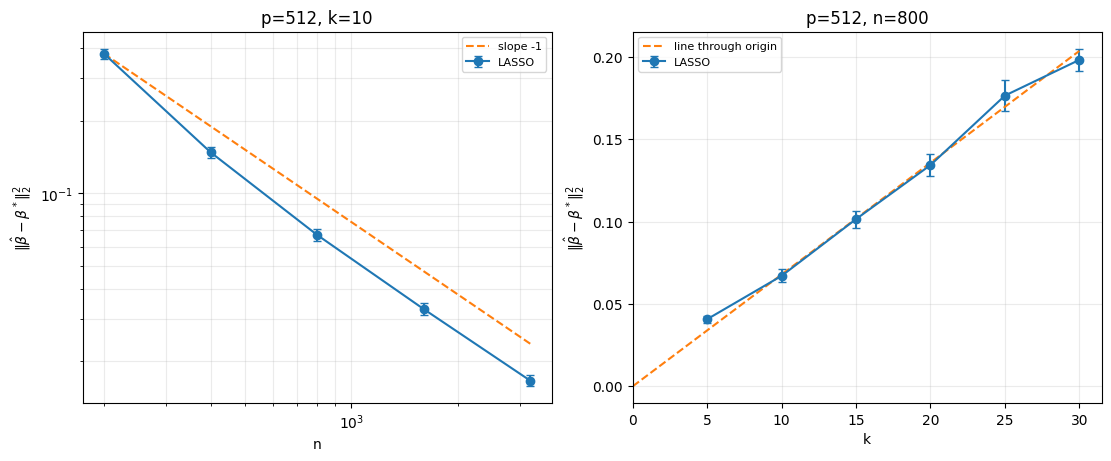

In [10]:
lookup = {(int(n), int(k)):(m,se) for n, k, m, se, _ in results}
mean_n = np.array([lookup[(int(n), 10)][0] for n in n_values])
sem_n = np.array([lookup[(int(n), 10)][1] for n in n_values])
mean_k = np.array([lookup[(800, int(k))][0] for k in k_values])
sem_k = np.array([lookup[(800, int(k))][1] for k in k_values])
slope, intercept = np.polyfit(np.log(n_values), np.log(mean_n), 1)
linear_coefficient = np.sum(k_values * mean_k) / np.sum(k_values**2)
print(f'loglog slope = {slope:.6f}; slope through origin (k) = {linear_coefficient:.6f}')
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
axs[0].errorbar(n_values, mean_n, yerr=sem_n, fmt='o-', capsize=3, label='LASSO')
axs[0].plot(n_values, mean_n[0] * n_values[0] / n_values, '--', label='slope -1')
axs[0].set(xscale='log', yscale='log', xlabel='n', ylabel=r"$\|\hat{\beta} - \beta^*\|^2_2$", title='p=512, k=10')
axs[0].legend(fontsize=8)
axs[0].grid(True, alpha=.25, which='both')
axs[1].errorbar(k_values, mean_k, yerr=sem_k, fmt='o-', capsize=3, label='LASSO')
axs[1].plot([0, *k_values], [0, *(linear_coefficient * k_values)], '--', label='line through origin')
axs[1].set(xlabel='k', ylabel=r"$\|\hat{\beta} - \beta^*\|^2_2$", title='p=512, n=800')
axs[1].set_xlim(left=0)
axs[1].legend(fontsize=8)
axs[1].grid(True, alpha=.25, which='both')
plt.show()

i. The loglog slope is $-1.12$, which is close to the theoretical slope of $-1$.
From lecture 8, the squared estimation error is bounded by $\frac{\sigma^2k\log p}{n}$,
so for a fixed $k = 10$, $p = 512$, and $\sigma = 1$, this predicts an inverse relationship
with $n$, which we see in the graph on the left. The differences arise from Monte
Carlo variability / random seed set.  
ii. Yes, there is a linear dependence on $k$ in $\frac{\sigma^2k\log p}{n}$, as
$p = 512$, $n = 800$, and $\sigma = 1$ (all fixed values). This is exemplified in 
the graph on the right, as the error increases roughly linearly as $k$ increases.

## (d)

In [12]:
p_k_values = [(128, 12), (256, 16), (512, 23), (1024, 32)]
r_values = np.array([1, 2, 3, 4, 6, 8, 12, 16])
configs = [(p, k, float(r), int(round(r * k * np.log(p)))) for p, k in p_k_values for r in r_values]

def run_config(p, k, r, n, seed):
    rng = np.random.default_rng(seed)
    sqerr = np.empty(T)
    lam = 0.5 * np.sqrt(2 * np.log(p) / n)
    with threadpool_limits(limits=1):
        for t in range(T):
            X = rng.standard_normal((n, p))
            beta = np.zeros(p)
            support = rng.choice(p, size=k, replace=False)
            beta[support] = rng.choice([-1.0, 1.0], size=k)
            eps = rng.normal(0, 1, size=n)
            y = X @ beta + eps
            fit = Lasso(alpha=lam, fit_intercept=False, max_iter=20000, tol=1e-7)
            fit.fit(X, y)
            sqerr[t] = np.sum((fit.coef_ - beta) ** 2)
    return p, k, r, n, float(sqerr.mean()), float(sqerr.std(ddof=1) / np.sqrt(T)), float(sqerr.std(ddof=1))

n_jobs = 8
seeds = np.random.SeedSequence(0).spawn(len(configs))
results = Parallel(n_jobs=n_jobs, backend='loky', verbose=10)(
    delayed(run_config)(p, k, r, n, seeds[i])
    for i, (p, k, r, n) in enumerate(configs)
)
np.savez("results_3d.npz", results=np.array(results), p_k_values=np.asarray(p_k_values), r_values=r_values, T=T, sigma=sigma)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    2.5s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    2.7s
[Parallel(n_jobs=8)]: Done  21 out of  32 | elapsed:    3.0s remaining:    1.5s
[Parallel(n_jobs=8)]: Done  25 out of  32 | elapsed:    3.3s remaining:    0.8s
[Parallel(n_jobs=8)]: Done  29 out of  32 | elapsed:    3.9s remaining:    0.3s
[Parallel(n_jobs=8)]: Done  32 out of  32 | elapsed:    5.4s finished


p= 128 k=12 r= 1 n=  58 mean=2.914070 SEM=0.276783
p= 128 k=12 r= 2 n= 116 mean=0.662994 SEM=0.050634
p= 128 k=12 r= 3 n= 175 mean=0.346022 SEM=0.024619
p= 128 k=12 r= 4 n= 233 mean=0.262795 SEM=0.021294
p= 128 k=12 r= 6 n= 349 mean=0.140581 SEM=0.008068
p= 128 k=12 r= 8 n= 466 mean=0.106751 SEM=0.007058
p= 128 k=12 r=12 n= 699 mean=0.070793 SEM=0.004387
p= 128 k=12 r=16 n= 932 mean=0.051654 SEM=0.003269
p= 256 k=16 r= 1 n=  89 mean=3.158824 SEM=0.299729
p= 256 k=16 r= 2 n= 177 mean=0.689777 SEM=0.058092
p= 256 k=16 r= 3 n= 266 mean=0.330009 SEM=0.019710
p= 256 k=16 r= 4 n= 355 mean=0.212843 SEM=0.012672
p= 256 k=16 r= 6 n= 532 mean=0.142003 SEM=0.006725
p= 256 k=16 r= 8 n= 710 mean=0.097944 SEM=0.004612
p= 256 k=16 r=12 n=1065 mean=0.059240 SEM=0.002601
p= 256 k=16 r=16 n=1420 mean=0.051249 SEM=0.002415
p= 512 k=23 r= 1 n= 143 mean=2.944675 SEM=0.349473
p= 512 k=23 r= 2 n= 287 mean=0.534898 SEM=0.024375
p= 512 k=23 r= 3 n= 430 mean=0.323961 SEM=0.019165
p= 512 k=23 r= 4 n= 574 mean=0.

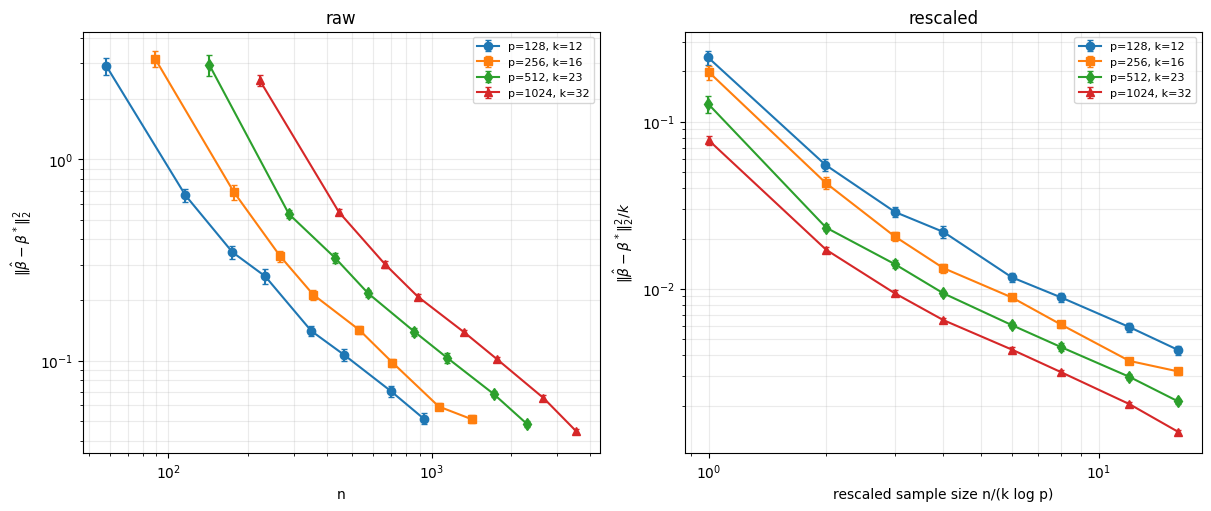

In [18]:
results = np.array(results)
for p, k, r, n, mean, sem, _ in results:
    print(f'p={p:4.0f} k={k:2.0f} r={r:2.0f} n={n:4.0f} mean={mean:.6f} SEM={sem:.6f}')
fig, axs = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
fmt_values = ['o-', 's-', 'd-', '^-']
for i, (p, k) in enumerate(p_k_values):
    rows = results[(results[:, 0]==p) & (results[:, 1]==k)]
    n, means, sem = rows[:, 3], rows[:, 4], rows[:, 5]
    r = rows[:, 3] / (k * np.log(p))
    axs[0].errorbar(n, means, yerr=sem, fmt=fmt_values[i], capsize=2, label=f'p={p}, k={k}')
    axs[1].errorbar(r ,means / k, yerr=sem / k, fmt=fmt_values[i], capsize=2, label=f'p={p}, k={k}')
axs[0].set(xscale='log', yscale='log', xlabel='n', ylabel=r"$\|\hat{\beta} - \beta^*\|^2_2$", title='raw')
axs[1].set(xscale='log', yscale='log', xlabel='rescaled sample size n/(k log p)', ylabel=r"$\|\hat{\beta} - \beta^*\|^2_2 / k$", title='rescaled')
axs[0].legend(fontsize=8)
axs[0].grid(True, alpha=.25, which='both')
axs[1].legend(fontsize=8)
axs[1].grid(True, alpha=.25, which='both')
plt.show()

The raw error curves do not collapse when plotted against $n$ because the estimation
error depends on the sparsity $k$ and the ambient dimension $p$, in addition to
the sample size. Rescaling the horizontal axis by $k \log p$ accounts for the sample
complexity in the bound, causing the curves to align more closely in shape. However,
the vertical rescaling do not perfectly collapse because the squared error bound
predicts with a remaining factor of $1/k$, which is why we still see some separation.
This shows that the ambient dimension $p$ enters the problem of sample complexity
only logarithmically, while the sparsity $k$ enteres linearly. Consequently,
increasing the number of features has a much weaker effect on the required sample
size than increasing the number of coefficients.

## (e)

In [25]:
p = 512
k = 10
n_values = np.array([200, 400, 800])
c_values = np.geomspace(0.03, 3, 11)

def run_config(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.standard_normal((n, p))
    beta = np.zeros(p)
    support = rng.choice(p, size=k, replace=False)
    beta[support] = rng.choice([-1.0, 1.0], size=k)
    y = X @ beta + rng.normal(0, sigma, size=n)
    lambda0 = sigma * np.sqrt(2 * np.log(p) / n)
    errors = np.empty(len(c_values))
    with threadpool_limits(limits=1):
        for i, c in enumerate(c_values):
            fit = Lasso(alpha=float(c * lambda0), fit_intercept=False, max_iter=20000, tol=1e-7)
            fit.fit(X, y)
            errors[i] = np.sum((fit.coef_ - beta) ** 2)
    return errors

configs = [(i, int(n), t) for i, n in enumerate(n_values) for t in range(T)]
seeds = np.random.SeedSequence(0).spawn(len(configs))
results = Parallel(n_jobs=8, backend='loky', verbose=10)(
    delayed(run_config)(n, seeds[i * T + t]) for i, n, t in configs
)
errors = np.asarray(results).reshape(len(n_values), T, len(c_values))
means = errors.mean(axis=1)
sems = errors.std(axis=1, ddof=1) / np.sqrt(T)
np.savez("results_3e.npz", errors=errors, means=means, sems=sems, n_values=n_values, c_values=c_values, p=p, k=k, T=T, sigma=sigma)

[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    2.6s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    2.8s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    2.9s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    3.0s
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    3.2s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:    3.4s
[Parallel(n_jobs=8)]: Done  52 out of  60 | elapsed:    3.5s remaining:    0.5s
[Parallel(n_jobs=8)]: Done  60 out of  60 | elapsed:    3.6s finished


Grid c: [0.03       0.0475468  0.07535659 0.11943215 0.1892872  0.3
 0.47546796 0.75356593 1.19432151 1.89287203 3.        ]
n=200, optimum c=0.47547, mean error=0.376258
means: [1.136864 1.009343 0.851425 0.675207 0.512646 0.392038 0.376258 0.551893
 1.174782 2.849869 6.513563]
n=400, optimum c=0.47547, mean error=0.150624
means: [1.586634 1.143507 0.778247 0.498768 0.306356 0.187052 0.150624 0.232959
 0.524424 1.277086 3.166984]
n=800, optimum c=0.47547, mean error=0.067693
means: [0.959803 0.72317  0.500575 0.314795 0.178131 0.094166 0.067693 0.106594
 0.244575 0.599161 1.492343]


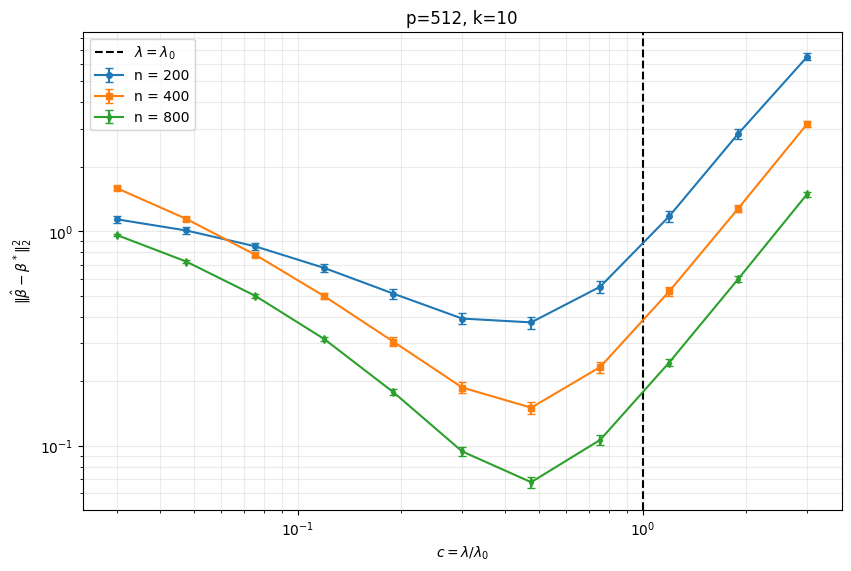

In [28]:
fig, ax = plt.subplots(figsize=(8.4, 5.6), layout='constrained')
fmt_values = ['o-', 's-', 'd-']
for i, n in enumerate(n_values):
    ax.errorbar(c_values, means[i], yerr=sems[i], fmt=fmt_values[i], capsize=3,
                linewidth=1.5, markersize=4, label=f'n = {n}')
ax.axvline(1.0, linestyle='--', color='black', label=r'$\lambda=\lambda_0$')
ax.set(xscale='log', yscale='log', xlabel=r'$c=\lambda/\lambda_0$',
        ylabel=r"$\|\hat{\beta} - \beta^*\|^2_2$",
        title='p=512, k=10')
ax.grid(True, which='both', alpha=0.25)
ax.legend()
print('Grid c:', c_values)
for i, n in enumerate(n_values):
    j = np.argmin(means[i]);print(f'n={n}, optimum c={c_values[j]:.5f}, mean error={means[i,j]:.6f}')
    print('means:',np.round(means[i],6))
plt.show()

The minimum occurs around $0.475\lambda_0$, which is close to the $\lambda_0/2$
used in parts (c) and (d). When $\lambda$ is too small, the $\ell_1$ penalty is weak,
allowing the LASSO to fit noise and include unecessary variables, which increases
the variance and estimation error. When $\lambda$ is too large, the penalty becomes
too strong, excessively shrinking the nonzero coefficients toward zero, which increases
bias and estimation error. This is why we see a U-shaped curve in the graph,
visualizing the bias-variance tradeoff, and also why the lowest errors occur
in middle $\lambda$ values. Our empirically optimal $\lambda$ in (a) was $0.92\lambda_0$.
From the proof in lecture 7, this would result in $1.84\lambda_0$, which is much larger
than the empirically optimal regularization level we got of $0.475\lambda_0$. This
difference is because the theoretical condition is designed to guarantee a high-probability
error bound, ensuring the noise term is controlled uniformly, whereas the simulation
minimizes average estimation error so a smaller value of $\lambda$ can perform
better empirically.